# 3. Exploratory plots — `be_scan.plot`

`be_scan.plot` is the quick-look layer: sensible defaults, ordinary keyword
arguments, matplotlib and plotly side by side.

Use it while you are still working out what the screen says. When you are
ready to make a figure for a paper, move to `be_scan.figure_plot`, covered in
notebook 4.

As of 3.0.0 every function here takes the **same** set of options. Whatever
you can do to a scatterplot you can do to a boxplot, a heatmap or a
correlation plot.

In [1]:
%matplotlib inline
import plotly.io as pio
# load plotly.js from a CDN in the rendered docs rather than
# embedding ~3 MB of it in every notebook output
pio.renderers.default = "notebook_connected"

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import be_scan.plot as bsp

scores = pd.read_csv("data/FOXA1_ABE_scores.csv")
print(scores.shape)
[c for c in scores.columns if "sorted_top" in c or c in
 ("sgRNA_ID", "gene", "AtoG_muttype", "AtoG_pos")]

(1292, 69)


['sgRNA_ID',
 'gene',
 'AtoG_muttype',
 'AtoG_pos',
 'sorted_top_LFCminusControl_avg',
 'sorted_top_LFCminusControl_stdev',
 'sorted_top-unsorted']

## The shared options

Every plotting function accepts these. The defaults are all "off", so adding
one only ever changes the plot when you ask it to.

| group | parameters |
|---|---|
| data | `df_filepath` — a DataFrame **or** a path to a csv |
| negative control | `neg_ctrl`, `neg_ctrl_col`, `neg_ctrl_conditions` |
| filter by value | `filter_val`, `val_cols`, `val_min` |
| filter by category | `filter_params`, `params_cols`, `params_conditions` |
| colour | `include_hue`, `hue_col`, `pal` |
| highlight | `highlight`, `highlight_col`, `highlight_vals` |
| labels | `xlab`, `ylab`, `title` |
| output | `savefig`, `show`, `out_name`, `out_type`, `out_dir`, `dpi` |

Each also returns `(fig, axes)` now, so you can keep customising after the
call.

## `scatterplot`

The workhorse: one panel per comparison, x is usually residue position.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


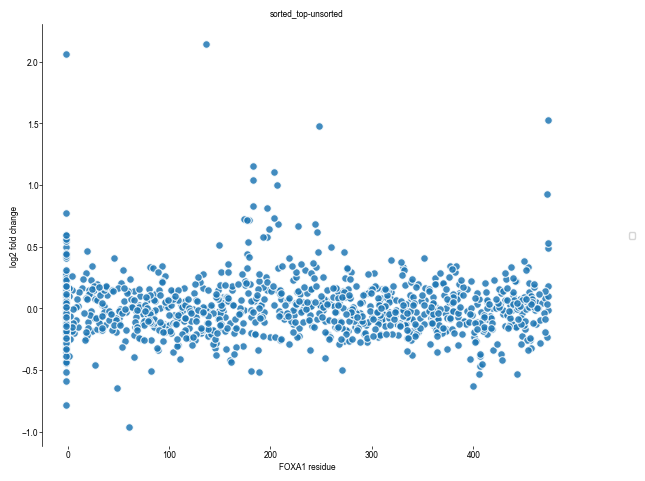

In [2]:
fig, axes = bsp.scatterplot(
    df_filepath = scores,
    comparisons = ["sorted_top-unsorted"],
    x_column    = "AtoG_pos",
    xlab = "FOXA1 residue", ylab = "log2 fold change",
    savefig = False,
)

Filtering to coding guides, colouring by mutation type, and normalizing to
the non-targeting controls. Note `xwindow`, which restricts the x range
*before* plotting rather than just cropping the axis.

Filter data by AtoG_muttype to contain:
['Missense', 'Nonsense', 'Silent']


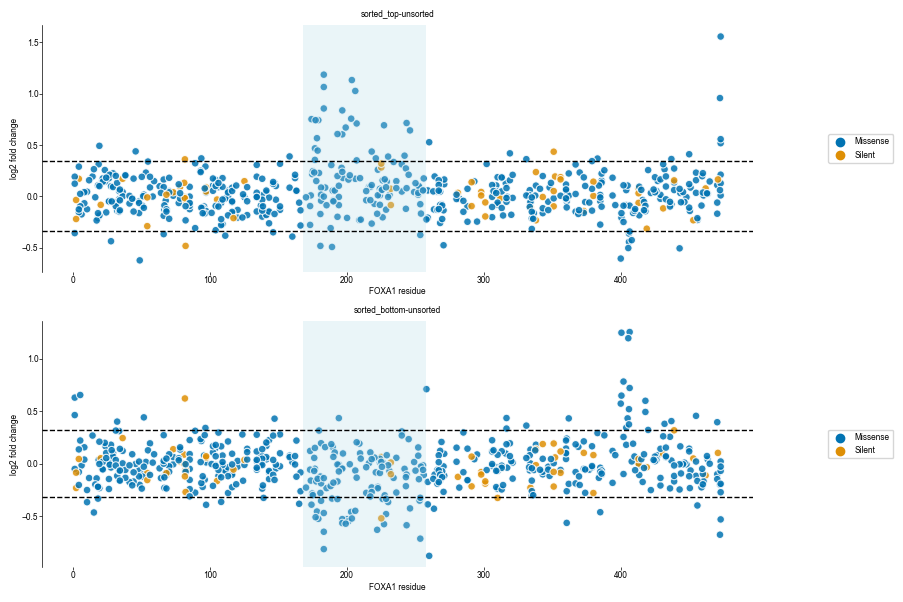

In [3]:
fig, axes = bsp.scatterplot(
    df_filepath = scores,
    comparisons = ["sorted_top-unsorted", "sorted_bottom-unsorted"],
    x_column    = "AtoG_pos",
    xwindow     = [1, 473],

    include_hue = True, hue_col = "AtoG_muttype", pal = "colorblind",
    filter_params = True, params_cols = ["AtoG_muttype"],
    params_conditions = [["Missense", "Nonsense", "Silent"]],

    neg_ctrl = True, neg_ctrl_col = "gene", neg_ctrl_conditions = ["Control"],
    domains  = [{"start": 168, "end": 258}],   # forkhead DNA-binding domain

    xlab = "FOXA1 residue", ylab = "log2 fold change",
    subplots_kws = {"figsize": (9, 6)},
    savefig = False,
)

### Annotating outliers

Four modes, and all four now work on every function that has comparisons:

- `annot_top=n` labels the n highest, `annot_top=-n` the n lowest
- `annot_abs=n` labels the n largest by absolute value
- `annot_cutoff=v` labels everything beyond +/- v

Filter data by AtoG_muttype to contain:
['Missense']


,Unnamed: 0.1,Unnamed: 0,sgRNA_ID,sgRNA_seq,PAM_seq,starting_frame,gene_pos,chr_pos,exon,windowstart_pos,...,sorted-bottom-3_LFCminusControl,unsorted_LFCminusControl_avg,unsorted_LFCminusControl_stdev,sorted_top_LFCminusControl_avg,sorted_top_LFCminusControl_stdev,sorted_bottom_LFCminusControl_avg,sorted_bottom_LFCminusControl_stdev,sorted_top-unsorted,sorted_bottom-unsorted,editor
707,707,981,sgRNA_981,GAGCTAGGAAGTGTTTAGGA,CGG,2.0,-1.0,37589958.0,1.0,1418.0,...,-1.369438,-1.007135,0.421788,0.520734,0.112694,-1.519491,0.342677,1.527870,-0.512356,ABE
873,873,653,sgRNA_653,GCTGGATGGCCATGGTGATG,AGC,0.0,552.0,37590827.0,1.0,549.0,...,-1.280185,-0.704638,0.137131,0.452374,0.174291,-1.334653,0.050114,1.157012,-0.630015,ABE
885,885,675,sgRNA_675,GGAAGAGGTCCATGATCCAC,TGG,0.0,612.0,37590767.0,1.0,609.0,...,-1.652854,-1.312694,0.497019,-0.208189,0.060353,-1.816395,0.144955,1.104505,-0.503701,ABE
614,614,654,sgRNA_654,CTGCTGGATGGCCATGGTGA,TGA,2.0,554.0,37590825.0,1.0,551.0,...,-1.286531,-0.462287,0.147053,0.574513,0.135185,-1.257066,0.180642,1.036800,-0.794779,ABE
1034,1034,676,sgRNA_676,GTAATAGGGGAAGAGGTCCA,TGA,2.0,620.0,37590759.0,1.0,617.0,...,-1.111336,-0.935001,0.119489,0.063517,0.324967,-1.365950,0.286290,0.998519,-0.430949,ABE
137,137,980,sgRNA_980,AGCTAGGAAGTGTTTAGGAC,GGG,1.0,-1.0,37589959.0,1.0,1417.0,...,-1.138831,-0.499781,0.145778,0.429534,0.148625,-1.157791,0.036814,0.929315,-0.658010,ABE
1240,1240,652,sgRNA_652,TGGATGGCCATGGTGATGAG,CGA,1.0,550.0,37590829.0,1.0,547.0,...,-1.143915,-0.516258,0.112383,0.311873,0.113544,-0.968032,0.152648,0.828131,-0.451774,ABE
1019,1019,668,sgRNA_668,GGTAGATCTCGCTCAGCGTG,AGC,0.0,591.0,37590788.0,1.0,588.0,...,-1.245468,-0.744455,0.101649,0.064913,0.254024,-1.291569,0.295232,0.809368,-0.547114,ABE


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


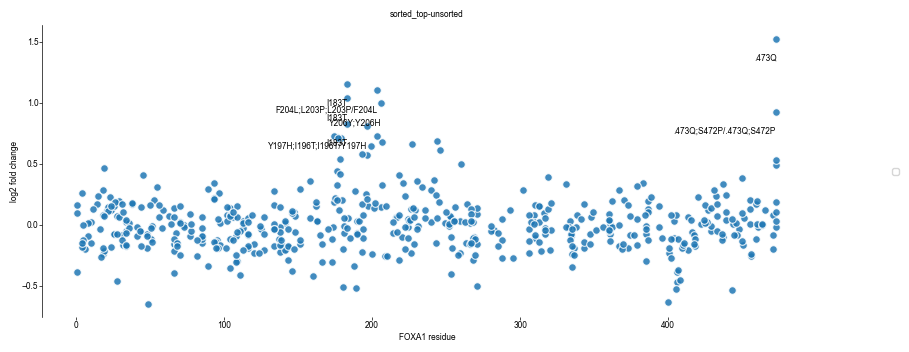

In [4]:
fig, axes = bsp.scatterplot(
    df_filepath = scores, comparisons = ["sorted_top-unsorted"],
    x_column = "AtoG_pos",
    filter_params = True, params_cols = ["AtoG_muttype"],
    params_conditions = [["Missense"]],
    annot = True, annot_label = "AtoG_mutations", annot_top = 8,
    xlab = "FOXA1 residue", ylab = "log2 fold change",
    subplots_kws = {"figsize": (9, 3.5)},
    savefig = False,
)

### Highlighting specific guides

New in 3.0.0 for every point-drawing function. Useful for showing where your
validation guides sit in the distribution.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


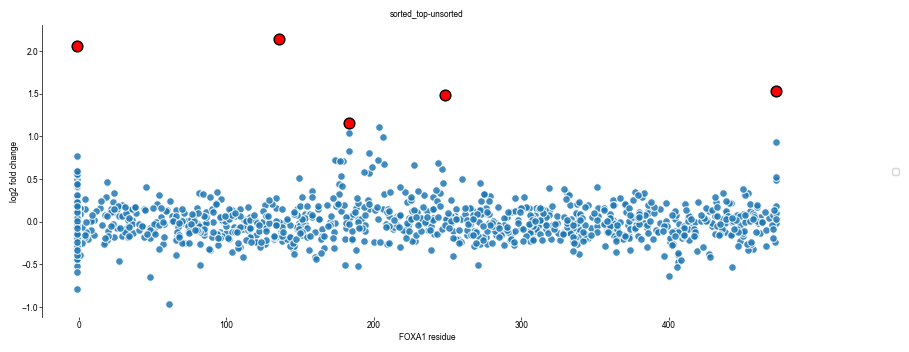

highlighted: ['sgRNA_154', 'Dep_cntrl_27', 'sgRNA_981', 'sgRNA_244', 'sgRNA_653']


In [5]:
picks = scores.nlargest(5, "sorted_top-unsorted")["sgRNA_ID"].tolist()

fig, axes = bsp.scatterplot(
    df_filepath = scores, comparisons = ["sorted_top-unsorted"],
    x_column = "AtoG_pos",
    highlight = True, highlight_col = "sgRNA_ID", highlight_vals = picks,
    xlab = "FOXA1 residue", ylab = "log2 fold change",
    subplots_kws = {"figsize": (9, 3.5)},
    savefig = False,
)
print("highlighted:", picks)

## `boxplot`

Distribution by category. Before 3.0.0 this had no hue, no filters and no
annotation; it now takes the same options as everything else.

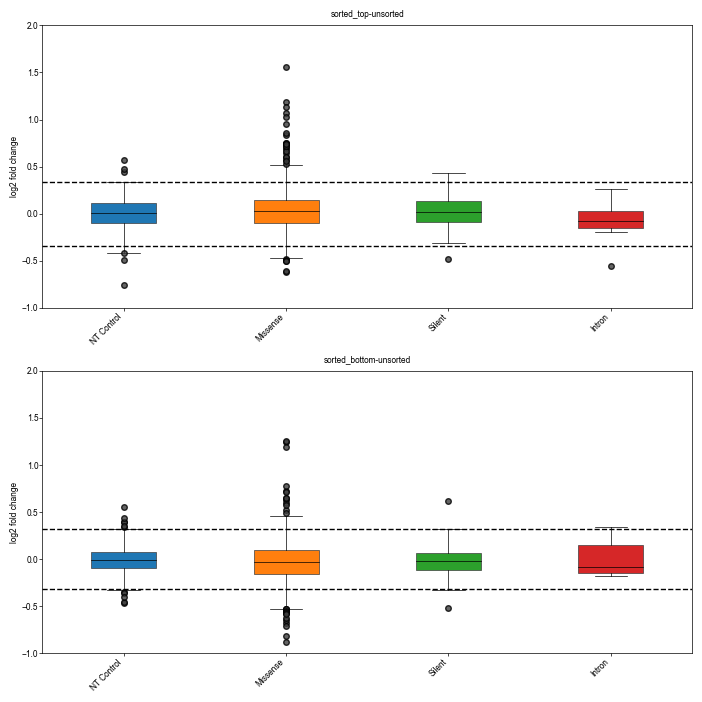

In [6]:
fig, axes = bsp.boxplot(
    df_filepath = scores,
    comparisons = ["sorted_top-unsorted", "sorted_bottom-unsorted"],
    plot_column = "AtoG_muttype",
    plot_conditions = ["Missense", "Nonsense", "Silent", "Intron", "NT Control"],
    neg_ctrl = True, neg_ctrl_col = "gene", neg_ctrl_conditions = ["Control"],
    ylab = "log2 fold change",
    subplots_kws = {"figsize": (7, 7)},
    savefig = False,
)

## `corr_heatmap`

Correlation between conditions. It gained the negative-control and filter
options in 3.0.0, so a heatmap and a scatterplot of the same columns now
agree about what they are showing.

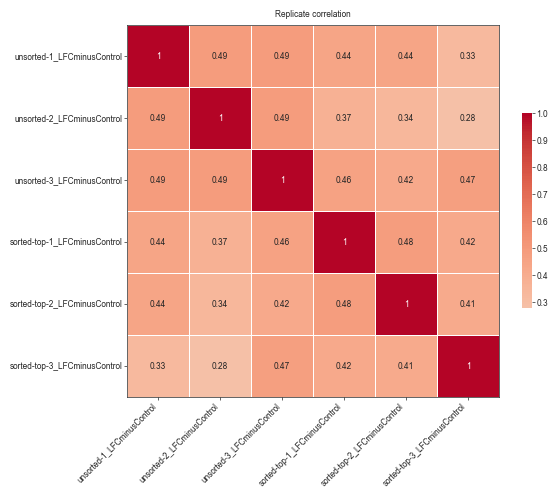

In [7]:
reps = ["unsorted-1_LFCminusControl", "unsorted-2_LFCminusControl",
        "unsorted-3_LFCminusControl",
        "sorted-top-1_LFCminusControl", "sorted-top-2_LFCminusControl",
        "sorted-top-3_LFCminusControl"]

fig, ax = bsp.corr_heatmap(
    df_filepath = scores, comparisons = reps,
    corr_type = "pearson",
    title = "Replicate correlation",
    subplots_kws = {"figsize": (6, 5)},
    savefig = False,
)

## `corr_jointplot`

Two conditions against each other, with marginal distributions and a printed
regression.

Filter data by AtoG_muttype to contain:
['Missense', 'Nonsense', 'Silent']
R: -0.18735535709477255 (p-value 5.554710308473559e-06)
R2: 0.03510202983210974


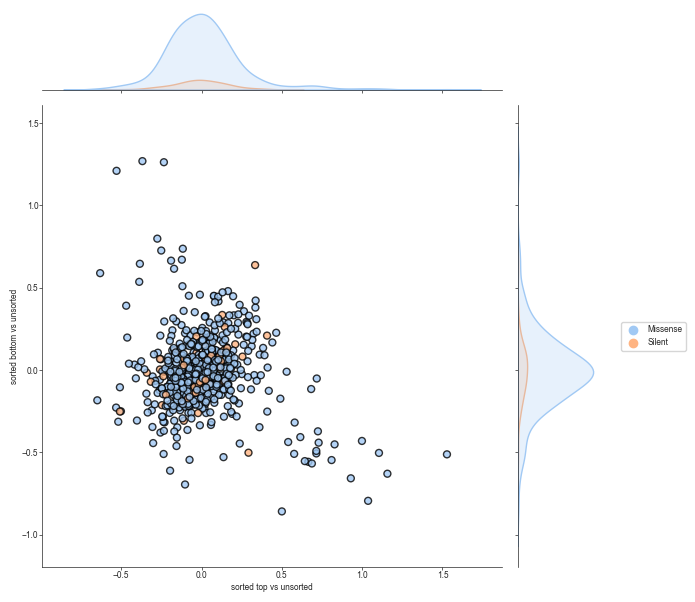

In [8]:
fig, ax = bsp.corr_jointplot(
    df_filepath = scores,
    condition1 = "sorted_top-unsorted", condition2 = "sorted_bottom-unsorted",
    include_hue = True, hue_col = "AtoG_muttype",
    filter_params = True, params_cols = ["AtoG_muttype"],
    params_conditions = [["Missense", "Nonsense", "Silent"]],
    xlab = "sorted top vs unsorted", ylab = "sorted bottom vs unsorted",
    savefig = False,
)

## `sgrna_enrichment`

Where a chosen set of guides falls in the overall distribution.

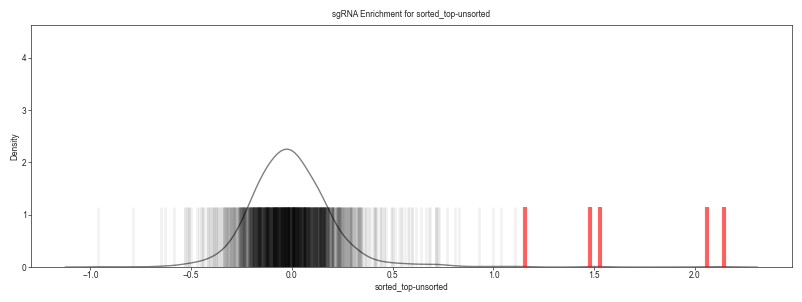

In [9]:
fig, ax = bsp.sgrna_enrichment(
    df_filepath = scores, comparisons = ["sorted_top-unsorted"],
    highlight = True, highlight_col = "sgRNA_ID", highlight_vals = picks,
    subplots_kws = {"figsize": (8, 3)},
    savefig = False,
)

## Interactive versions

Four functions have a plotly twin taking the same arguments. They render in
the notebook and write a standalone `.html` when `savefig=True`.

In [10]:
bsp.interactive_scatter(
    df_filepath = scores, comparisons = ["sorted_top-unsorted"],
    x_column = "AtoG_pos",
    annot_label = "AtoG_mutations",
    include_hue = True, hue_col = "AtoG_muttype",
    filter_params = True, params_cols = ["AtoG_muttype"],
    params_conditions = [["Missense", "Nonsense", "Silent"]],
    xlab = "FOXA1 residue", ylab = "log2 fold change",
    savefig = False,
)

Filter data by AtoG_muttype to contain:
['Missense', 'Nonsense', 'Silent']


In [11]:
bsp.interactive_corr_heatmap(
    df_filepath = scores, comparisons = reps,
    title = "Replicate correlation",
    savefig = False,
)

## `loess_smoothing`

Fits a LOESS curve along the protein and tests it against randomised data, so
it finds *regions* of the protein that behave unusually rather than
individual guides. It returns a results dict; pass it to `plot_loess`.

```python
from be_scan.plot.loess_smoothing import loess_smoothing, plot_loess

coding = scores[scores["AtoG_muttype"] == "Missense"]
results = loess_smoothing(
    df = coding, x_column = "AtoG_pos",
    comparisons = ["sorted_top-unsorted"],
    span = 20, n_repeats = 1000,
)
plot_loess(results, gene = "FOXA1", domains = [{"start": 168, "end": 258}])
```

`n_repeats` drives the runtime: 1,000 takes a few seconds, 10,000 a couple of
minutes.